# Climate Change Analytics — CIPAT Project


### Topic D — Custom Module
We write our own `climate_utils.py` module to disk with `%%writefile`, then `import` it just like any other package. It holds the custom exceptions, the synthetic-data generator, statistics helpers, and the SQLite CRUD wrapper used throughout this notebook.

In [ ]:
%%writefile climate_utils.py
"""
climate_utils.py
-----------------
Custom module for the "Climate Change Analytics" CIPAT project.

Contains:
  * Custom exception classes            (Topic E - Exception Handling)
  * A reproducible synthetic climate-data generator
  * Reusable statistics / preprocessing helper functions
  * A tiny SQLite CRUD wrapper           (Topic H - CRUD Operations)

Import this module from your main script / notebook with:
    import climate_utils as cu
"""

import sqlite3

import numpy as np
import pandas as pd
from scipy import stats


# =====================================================================
# CUSTOM EXCEPTIONS   (Topic E: Exception Handling)
# =====================================================================
class DataValidationError(Exception):
    """Raised when the climate dataset fails a validation check."""
    pass


class ScrapingError(Exception):
    """Raised when a web-scraping request fails or returns unexpected data."""
    pass

# =====================================================================
# SYNTHETIC DATASET GENERATOR
# =====================================================================
# 15 countries with realistic baseline temperature (deg C) and
# baseline CO2 emissions (Million Tonnes) used to seed the simulation.
COUNTRIES = ["USA", "China", "India", "Germany", "Brazil", "Australia",
             "Japan", "United Kingdom", "France", "Canada", "Russia",
             "South Africa", "Indonesia", "Mexico", "Saudi Arabia"]

_BASE_TEMP = dict(zip(COUNTRIES,
    [12.9, 8.5, 24.5, 9.6, 24.9, 21.6, 11.9, 9.3, 11.2, -2.5,
     -5.1, 17.7, 26.0, 21.0, 26.3]))

_BASE_CO2 = dict(zip(COUNTRIES,
    [5000, 3000, 900, 900, 350, 400, 1100, 550, 350, 550, 1600,
     400, 450, 400, 500]))


def generate_synthetic_climate_data(start_year=1990, end_year=2023, seed=42):
    """
    Generates a reproducible synthetic global climate dataset spanning
    `start_year`-`end_year` for every country in COUNTRIES.

    Returns
    -------
    pandas.DataFrame with columns:
        Year, Country, Avg_Temperature_C, CO2_Emissions_MT,
        Sea_Level_Rise_mm, Precipitation_mm,
        Renewable_Energy_Percent, Extreme_Weather_Events
    """
    rng = np.random.default_rng(seed)
    years = np.arange(start_year, end_year + 1)
    rows = []

    for country in COUNTRIES:
        base_temp = _BASE_TEMP[country]
        base_co2 = _BASE_CO2[country]
        for i, year in enumerate(years):
            warming = 0.02 * i + rng.normal(0, 0.15)
            temp = base_temp + warming

            co2 = base_co2 * (1.015 ** i) * rng.uniform(0.95, 1.05)
            sea_level = 0.5 * i + rng.normal(0, 1.0)
            precipitation = rng.normal(1000, 150)
            renewable_pct = max(0, min(60, 5 + 0.6 * i + rng.normal(0, 2)))
            extreme_events = rng.poisson(2 + 0.05 * i)

            rows.append([year, country, round(temp, 2), round(co2, 2),
                         round(sea_level, 2), round(precipitation, 1),
                         round(renewable_pct, 2), int(extreme_events)])

    return pd.DataFrame(rows, columns=[
        "Year", "Country", "Avg_Temperature_C", "CO2_Emissions_MT",
        "Sea_Level_Rise_mm", "Precipitation_mm",
        "Renewable_Energy_Percent", "Extreme_Weather_Events"
    ])
# =====================================================================
# PREPROCESSING / STATISTICS HELPERS
# =====================================================================
def detect_outliers_iqr(series):
    """Boolean mask marking IQR-based outliers in a pandas Series."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < lower) | (series > upper)


def min_max_normalize(series):
    """Min-max scales a pandas Series into the [0, 1] range."""
    return (series - series.min()) / (series.max() - series.min())


def confidence_interval(data, confidence=0.95):
    """Returns (point_estimate, lower_bound, upper_bound) for the mean."""
    data = np.asarray(data)
    n = len(data)
    mean = np.mean(data)
    sem = stats.sem(data)
    margin = sem * stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean, mean - margin, mean + margin


def celsius_to_fahrenheit(temp_c):
    """Simple unit-conversion helper (works on scalars or numpy arrays)."""
    return temp_c * 9 / 5 + 32


def classify_risk_level(temp_anomaly, co2, events):
    """
    Rule-based climate-risk label used as ground truth before training
    the Random Forest classifier in the Machine Learning section.
    """
    score = (temp_anomaly * 2) + (co2 / 1000) + (events * 1.5)
    if score < 5:
        return "Low"
    elif score < 12:
        return "Medium"
    else:
        return "High"

# =====================================================================
# CRUD WRAPPER  (Topic H: CRUD Operations, backed by SQLite)
# =====================================================================
class ClimateDB:
    """A tiny SQLite wrapper demonstrating Create/Read/Update/Delete."""

    def __init__(self, db_path="climate_data.db"):
        self.db_path = db_path
        self.conn = sqlite3.connect(db_path)
        self._create_table()

    def _create_table(self):
        self.conn.execute("""
            CREATE TABLE IF NOT EXISTS climate_records (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                year INTEGER,
                country TEXT,
                avg_temperature REAL,
                co2_emissions REAL
            )
        """)
        self.conn.commit()

    # ---- CREATE ----
    def insert_record(self, year, country, avg_temperature, co2_emissions):
        cur = self.conn.execute(
            "INSERT INTO climate_records (year, country, avg_temperature, co2_emissions) "
            "VALUES (?, ?, ?, ?)",
            (year, country, avg_temperature, co2_emissions)
        )
        self.conn.commit()
        return cur.lastrowid

    # ---- READ ----
    def fetch_all(self, limit=10):
        cur = self.conn.execute(
            "SELECT * FROM climate_records LIMIT ?", (limit,))
        return cur.fetchall()

    def fetch_by_country(self, country):
        cur = self.conn.execute(
            "SELECT * FROM climate_records WHERE country = ?", (country,))
        return cur.fetchall()

    # ---- UPDATE ----
    def update_temperature(self, record_id, new_temp):
        self.conn.execute(
            "UPDATE climate_records SET avg_temperature = ? WHERE id = ?",
            (new_temp, record_id)
        )
        self.conn.commit()

    # ---- DELETE ----
    def delete_record(self, record_id):
        self.conn.execute(
            "DELETE FROM climate_records WHERE id = ?", (record_id,))
        self.conn.commit()

    def close(self):
        self.conn.close()


Writing climate_utils.py


### Topic C — Python Libraries
Import every standard-library and third-party package used in this project (the custom module `climate_utils` covers **Topic D — Custom Modules**, written to disk in the cell above so this notebook is self-contained on Colab).

In [ ]:
import os
import json
import random
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                              classification_report, confusion_matrix)

import requests
from bs4 import BeautifulSoup

# SECTION D : CUSTOM MODULE (must sit next to this file)
import climate_utils as cu

sns.set_theme(style="darkgrid")
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("=" * 70)
print("CLIMATE CHANGE ANALYTICS -- CIPAT PROJECT")
print("=" * 70)


CLIMATE CHANGE ANALYTICS -- CIPAT PROJECT


### Topic A — Python Core Concepts
Variables, functions, `f-strings`, `lambda`, list comprehensions, loops and conditionals.

In [ ]:
print("\n[SECTION A] Python Core Concepts")


def greet_team(members):
    """Function + f-strings + loop demo."""
    for i, name in enumerate(members, start=1):
        print(f"  Member {i}: {name}")


team_members = ["Student 1", "Student 2", "Student 3", "Student 4"]
greet_team(team_members)

square_lambda = lambda x: x ** 2                      # lambda function
squares = [square_lambda(n) for n in range(1, 6)]     # list comprehension
print(f"  Squares 1-5 via lambda + comprehension: {squares}")

for year in [1990, 2000, 2010, 2020]:                 # loop + conditional
    era = "20th century" if year < 2000 else "21st century"
    print(f"  Year {year} -> {era}")



[SECTION A] Python Core Concepts
  Member 1: Student 1
  Member 2: Student 2
  Member 3: Student 3
  Member 4: Student 4
  Squares 1-5 via lambda + comprehension: [1, 4, 9, 16, 25]
  Year 1990 -> 20th century
  Year 2000 -> 21st century
  Year 2010 -> 21st century
  Year 2020 -> 21st century


### Topic B — Data Structures
Lists, tuples, dictionaries and sets applied to the climate data.

In [ ]:
print("\n[SECTION B] Data Structures")

countries_list = cu.COUNTRIES                              # list
sample_tuple = ("USA", 2023, 13.9)                          # tuple
country_temp_dict = {"USA": 13.9, "India": 25.1, "Germany": 10.2}  # dict
unique_years = {1990, 1995, 1995, 2000}                     # set (dedups)

print(f"  Countries (list, first 5): {countries_list[:5]}")
print(f"  Sample record (tuple): {sample_tuple}")
print(f"  Country -> Temp (dict): {country_temp_dict}")
print(f"  Unique years (set): {unique_years}")



[SECTION B] Data Structures
  Countries (list, first 5): ['USA', 'China', 'India', 'Germany', 'Brazil']
  Sample record (tuple): ('USA', 2023, 13.9)
  Country -> Temp (dict): {'USA': 13.9, 'India': 25.1, 'Germany': 10.2}
  Unique years (set): {2000, 1995, 1990}


### Topics D & E — Custom Modules + Exception Handling
Generate the working dataset using the functions imported from our own `climate_utils` module, and demonstrate `try / except / finally` with both a custom exception and built-in exceptions (`ZeroDivisionError`, `FileNotFoundError`).

In [ ]:
print("\n[SECTION D/E] Custom Module + Exception Handling")

try:
    df = cu.generate_synthetic_climate_data(1990, 2023, seed=RANDOM_SEED)
    if df.empty:
        raise cu.DataValidationError("Generated dataset is empty!")
    print(f"  Generated dataset via custom module: "
          f"{df.shape[0]} rows x {df.shape[1]} columns")
except cu.DataValidationError as e:
    print(f"  Data validation failed: {e}")
    raise
finally:
    print("  Dataset generation step complete.")

try:                                    # deliberate error, caught safely
    _ = 10 / 0
except ZeroDivisionError as e:
    print(f"  Caught expected error: {e}")

try:                                    # deliberate missing-file error
    _ = pd.read_csv("does_not_exist.csv")
except FileNotFoundError as e:
    print(f"  Caught expected file error: {type(e).__name__}")



[SECTION D/E] Custom Module + Exception Handling
  Generated dataset via custom module: 510 rows x 8 columns
  Dataset generation step complete.
  Caught expected error: division by zero
  Caught expected file error: FileNotFoundError


### Topic F — Web Scraping
Attempts a **live** scrape of a Wikipedia CO2-emissions table with `requests` + `BeautifulSoup`. If there's no internet access or the page structure changes, it falls back to the generated dataset instead of crashing — this fallback *is* the Exception Handling topic in action.

In [ ]:
print("\n[SECTION F] Web Scraping")


def scrape_co2_table(url="https://en.wikipedia.org/wiki/"
                          "List_of_countries_by_carbon_dioxide_emissions"):
    """Tries to scrape a live CO2-emissions table from Wikipedia."""
    try:
        resp = requests.get(url, timeout=10,
                             headers={"User-Agent": "Mozilla/5.0"})
        resp.raise_for_status()
        soup = BeautifulSoup(resp.text, "html.parser")
        table = soup.find("table", {"class": "wikitable"})
        if table is None:
            raise cu.ScrapingError("Expected table not found on page.")
        return pd.read_html(str(table))[0]
    except (requests.RequestException, cu.ScrapingError, ValueError) as e:
        print(f"  Scraping unavailable ({type(e).__name__}); "
              f"falling back to the generated dataset instead.")
        return None


scraped_df = scrape_co2_table()
if scraped_df is not None:
    print("  Live scrape succeeded -- preview:")
    print(scraped_df.head())
else:
    scraped_df = (df.groupby("Country")["CO2_Emissions_MT"].mean()
                    .reset_index()
                    .sort_values("CO2_Emissions_MT", ascending=False))
    print("  Using locally aggregated CO2 totals instead:")
    print(scraped_df.head().to_string(index=False))



[SECTION F] Web Scraping


/tmp/ipykernel_2961/3863220877.py:15: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  return pd.read_html(str(table))[0]


  Live scrape succeeded -- preview:
                     Location % of global total  \
                     Location % of global total   
0                       World              100%   
1                       China             34.0%   
2               United States             12.0%   
3                       India              7.6%   
4  European Union post-Brexit              6.5%   

  Fossil emissions (1,000,000 tons per year)           % change from 2000  
                                        2023      2000 % change from 2000  
0                                   39023.94  25725.44               +52%  
1                                   13259.64   3666.95              +262%  
2                                    4682.04   5928.97               −21%  
3                                    2955.18    995.65              +197%  
4                                    2517.27   3566.76               −29%  


### Topic G — File Handling
Write the dataset to CSV, write a JSON summary, and append to a plain-text log file, then read the CSV back from disk.

In [ ]:
print("\n[SECTION G] File Handling")

DATA_DIR = "climate_project_files"
os.makedirs(DATA_DIR, exist_ok=True)

csv_path = os.path.join(DATA_DIR, "climate_data.csv")
df.to_csv(csv_path, index=False)
print(f"  Wrote dataset to {csv_path}")

df_loaded = pd.read_csv(csv_path)
print(f"  Re-loaded {len(df_loaded)} rows from disk")

summary = {
    "generated_on": str(dt.datetime.now()),
    "rows": len(df_loaded),
    "countries": int(df_loaded["Country"].nunique()),
    "year_range": [int(df_loaded.Year.min()), int(df_loaded.Year.max())],
}
json_path = os.path.join(DATA_DIR, "summary.json")
with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"  Wrote summary metadata to {json_path}")

log_path = os.path.join(DATA_DIR, "run_log.txt")
with open(log_path, "a") as f:
    f.write(f"{dt.datetime.now()} - analysis run completed\n")
print(f"  Appended a line to {log_path}")



[SECTION G] File Handling
  Wrote dataset to climate_project_files/climate_data.csv
  Re-loaded 510 rows from disk
  Wrote summary metadata to climate_project_files/summary.json
  Appended a line to climate_project_files/run_log.txt


### Topic H — CRUD Operations
A small SQLite database (`climate_data.db`) demonstrates real **Create / Read / Update / Delete** operations through the `ClimateDB` class in our custom module.

In [ ]:
print("\n[SECTION H] CRUD Operations")

db_path = os.path.join(DATA_DIR, "climate_data.db")
db = cu.ClimateDB(db_path)

sample_rows = df_loaded.sample(5, random_state=RANDOM_SEED)
inserted_ids = [
    db.insert_record(int(r.Year), r.Country,
                      float(r.Avg_Temperature_C), float(r.CO2_Emissions_MT))
    for r in sample_rows.itertuples()
]
print(f"  CREATE: inserted {len(inserted_ids)} records, ids={inserted_ids}")
print("  READ  :", db.fetch_all(limit=3))

db.update_temperature(inserted_ids[0], 99.9)
print("  UPDATE: record", inserted_ids[0], "is now",
      [r for r in db.fetch_all(limit=len(inserted_ids)) if r[0] == inserted_ids[0]])

db.delete_record(inserted_ids[-1])
print(f"  DELETE: removed record {inserted_ids[-1]}")
print("  Remaining rows in table:", len(db.fetch_all(limit=1000)))
db.close()



[SECTION H] CRUD Operations
  CREATE: inserted 5 records, ids=[1, 2, 3, 4, 5]
  READ  : [(1, 1994, 'Saudi Arabia', 26.55, 554.03), (2, 1997, 'Mexico', 21.36, 450.17), (3, 2023, 'Mexico', 21.67, 686.37)]
  UPDATE: record 1 is now [(1, 1994, 'Saudi Arabia', 99.9, 554.03)]
  DELETE: removed record 5
  Remaining rows in table: 4


### Topic I — NumPy
Array creation, vectorised operations, broadcasting and percentile / mean / std statistics.

In [ ]:
print("\n[SECTION I] NumPy")

temp_array = df_loaded["Avg_Temperature_C"].to_numpy()
co2_array = df_loaded["CO2_Emissions_MT"].to_numpy()

print(f"  Temperature array shape: {temp_array.shape}")
print(f"  Mean temp: {temp_array.mean():.2f} degC | Std: {temp_array.std():.2f}")
print(f"  90th percentile CO2: {np.percentile(co2_array, 90):.1f} MT")

temp_f = cu.celsius_to_fahrenheit(temp_array)             # vectorised op
print(f"  First 5 temps in F: {np.round(temp_f[:5], 1)}")

anomaly = temp_array - temp_array.mean()                  # broadcasting
print(f"  Largest positive anomaly: {anomaly.max():.2f} degC")



[SECTION I] NumPy
  Temperature array shape: (510,)
  Mean temp: 14.84 degC | Std: 9.53
  90th percentile CO2: 3799.7 MT
  First 5 temps in F: [55.3 55.  55.4 55.5 55.7]
  Largest positive anomaly: 12.35 degC


### Topic J — SciPy
Pearson correlation (`scipy.stats`) and non-linear/linear curve fitting (`scipy.optimize.curve_fit`) to quantify the warming trend.

In [ ]:
print("\n[SECTION J] SciPy")

yearly_mean = df_loaded.groupby("Year")["Avg_Temperature_C"].mean()

# NOTE: correlation is computed on the yearly *global* mean, not on the raw
# pooled rows -- raw rows mix in each country's very different baseline
# climate (e.g. Russia vs Saudi Arabia), which would swamp the warming
# signal we actually care about.
corr, p_value = stats.pearsonr(yearly_mean.index, yearly_mean.values)
print(f"  Year vs Global-Mean-Temperature Pearson r = {corr:.3f} (p={p_value:.2e})")


def linear_model(x, a, b):
    return a * x + b


popt, _ = curve_fit(linear_model, yearly_mean.index, yearly_mean.values)
print(f"  Fitted warming trend: {popt[0] * 10:.3f} degC per decade")



[SECTION J] SciPy
  Year vs Global-Mean-Temperature Pearson r = 0.975 (p=2.03e-22)
  Fitted warming trend: 0.199 degC per decade


### Topic K — Pandas
DataFrame exploration, filtering, `groupby`, and `pivot_table`.

In [ ]:
print("\n[SECTION K] Pandas")

print(df_loaded.describe().T[["mean", "std", "min", "max"]])

top5_co2 = (df_loaded[df_loaded.Year == 2023]
            .sort_values("CO2_Emissions_MT", ascending=False)
            .head(5)[["Country", "CO2_Emissions_MT"]])
print("\n  Top-5 CO2 emitters in 2023:")
print(top5_co2.to_string(index=False))

pivot = df_loaded.pivot_table(index="Year", columns="Country",
                               values="Avg_Temperature_C", aggfunc="mean")
print(f"\n  Pivot table shape (Year x Country): {pivot.shape}")

decade_group = (df_loaded.assign(Decade=(df_loaded.Year // 10) * 10)
                .groupby("Decade")[["Avg_Temperature_C", "CO2_Emissions_MT"]]
                .mean())
print("\n  Decade-wise averages:")
print(decade_group)



[SECTION K] Pandas
                                 mean          std      min      max
Year                      2006.500000     9.820341  1990.00  2023.00
Avg_Temperature_C           14.844608     9.544166    -5.22    27.19
CO2_Emissions_MT          1415.082980  1633.784903   335.89  8464.62
Sea_Level_Rise_mm            8.241235     4.969018    -1.53    18.86
Precipitation_mm           997.324314   148.217135   624.70  1373.90
Renewable_Energy_Percent    14.822529     6.273643     1.10    29.22
Extreme_Weather_Events       2.884314     1.706439     0.00     9.00

  Top-5 CO2 emitters in 2023:
Country  CO2_Emissions_MT
    USA           8464.62
  China           5133.81
 Russia           2573.36
  Japan           1803.91
  India           1466.39

  Pivot table shape (Year x Country): (34, 15)

  Decade-wise averages:
        Avg_Temperature_C  CO2_Emissions_MT
Decade                                     
1990            14.613867       1169.985600
2000            14.796200       1363

### Topic L — Data Preprocessing
Missing-value imputation, IQR-based outlier capping, min-max normalization, and both **label encoding** and (later, in Topic R) **one-hot encoding** of the `Country` column.

In [ ]:
print("\n[SECTION L] Data Preprocessing")

proc_df = df_loaded.copy()

rng = np.random.default_rng(RANDOM_SEED)
missing_idx = rng.choice(proc_df.index, size=15, replace=False)
proc_df.loc[missing_idx, "Precipitation_mm"] = np.nan
print(f"  Injected {proc_df['Precipitation_mm'].isna().sum()} missing values")

proc_df["Precipitation_mm"] = proc_df["Precipitation_mm"].fillna(
    proc_df["Precipitation_mm"].median())
print("  Filled missing values with the column median")

outlier_mask = cu.detect_outliers_iqr(proc_df["CO2_Emissions_MT"])
print(f"  Detected {outlier_mask.sum()} CO2 outliers (IQR method)")
q1, q3 = proc_df["CO2_Emissions_MT"].quantile([0.25, 0.75])
iqr = q3 - q1
proc_df["CO2_Emissions_MT"] = proc_df["CO2_Emissions_MT"].clip(
    q1 - 1.5 * iqr, q3 + 1.5 * iqr)

proc_df["Temp_Normalized"] = cu.min_max_normalize(proc_df["Avg_Temperature_C"])

le = LabelEncoder()
proc_df["Country_Encoded"] = le.fit_transform(proc_df["Country"])
print(f"  Encoded {proc_df['Country_Encoded'].nunique()} countries")

proc_df["Temp_Anomaly"] = (proc_df["Avg_Temperature_C"]
                            - proc_df.groupby("Country")["Avg_Temperature_C"]
                                      .transform("min"))
proc_df["Risk_Level"] = proc_df.apply(
    lambda r: cu.classify_risk_level(r.Temp_Anomaly, r.CO2_Emissions_MT,
                                      r.Extreme_Weather_Events), axis=1)
print("  Risk-level distribution:")
print(proc_df["Risk_Level"].value_counts())



[SECTION L] Data Preprocessing
  Injected 15 missing values
  Filled missing values with the column median
  Detected 68 CO2 outliers (IQR method)
  Encoded 15 countries
  Risk-level distribution:
Risk_Level
Medium    311
Low       181
High       18
Name: count, dtype: int64


### Topic M — Data Visualization
Six charts in one dashboard: trend line, bar chart, scatter plot, histogram, boxplot and a correlation heatmap.


[SECTION M] Data Visualization (figures saved to 'climate_project_files/')


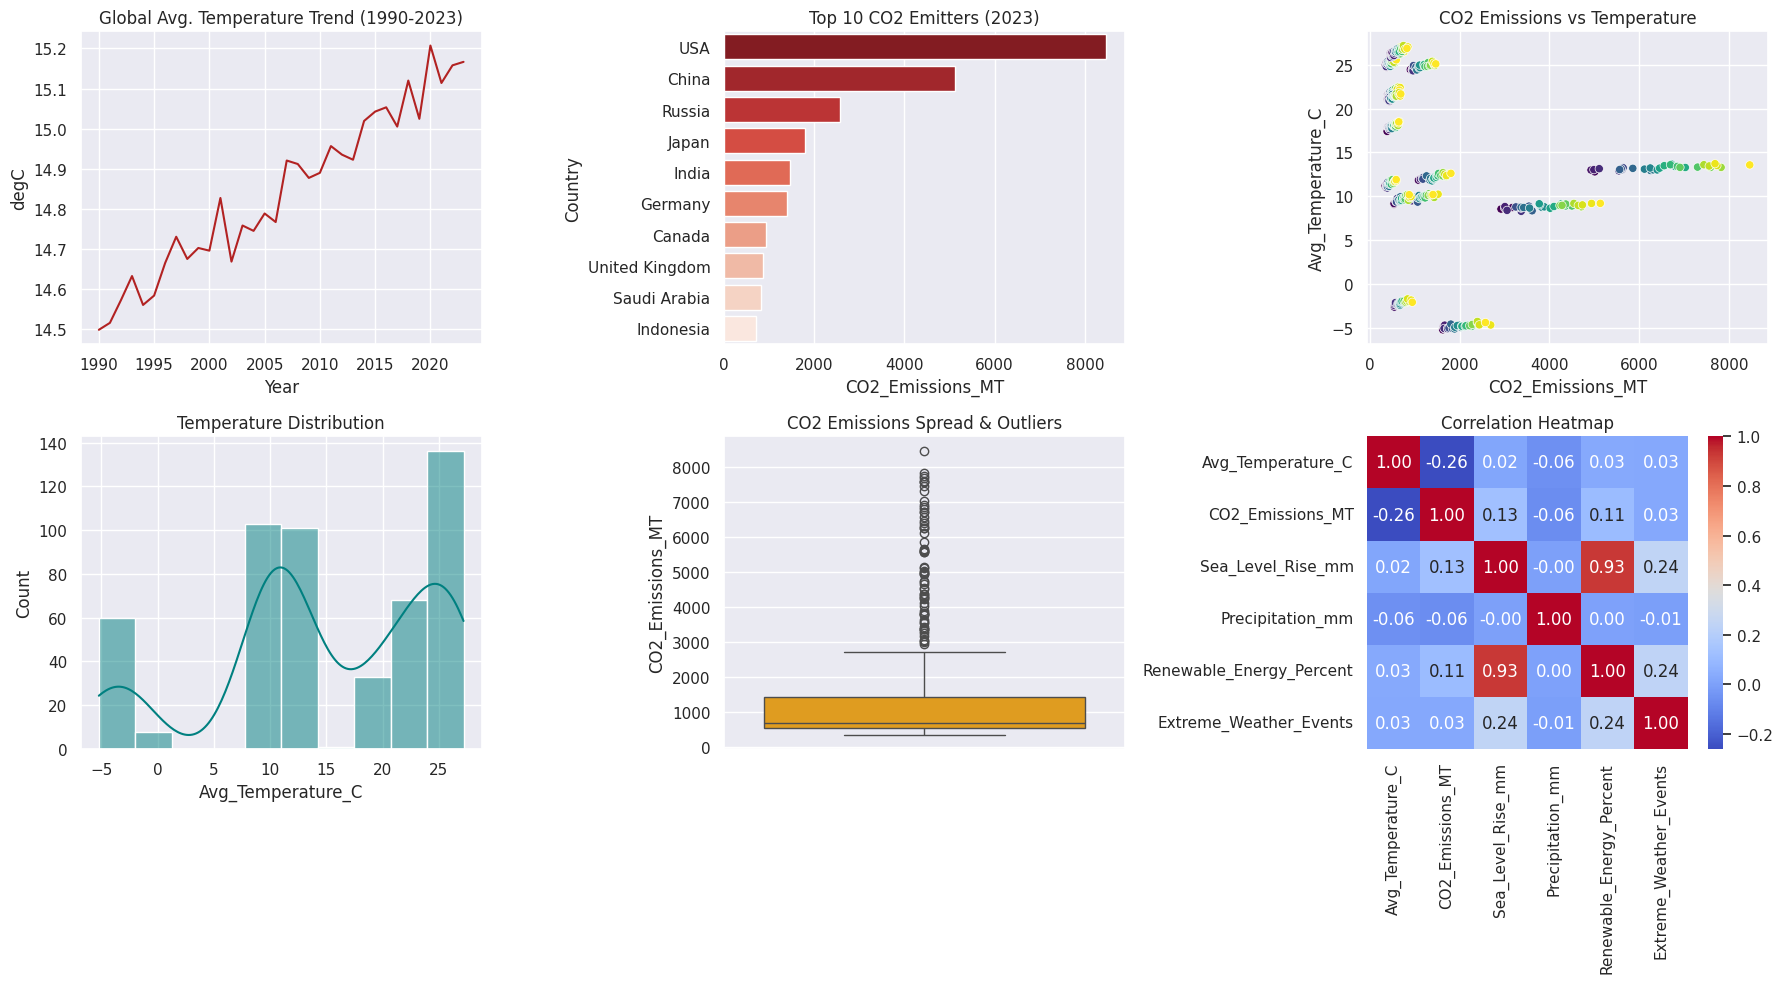

  Saved combined dashboard to climate_project_files/climate_dashboard.png


In [ ]:
print(f"\n[SECTION M] Data Visualization (figures saved to '{DATA_DIR}/')")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

yearly_mean.plot(ax=axes[0, 0], color="firebrick")
axes[0, 0].set_title("Global Avg. Temperature Trend (1990-2023)")
axes[0, 0].set_ylabel("degC")

top10 = (df_loaded[df_loaded.Year == 2023]
         .sort_values("CO2_Emissions_MT", ascending=False).head(10))
sns.barplot(data=top10, x="CO2_Emissions_MT", y="Country",
            ax=axes[0, 1], hue="Country", palette="Reds_r", legend=False)
axes[0, 1].set_title("Top 10 CO2 Emitters (2023)")

sns.scatterplot(data=df_loaded, x="CO2_Emissions_MT", y="Avg_Temperature_C",
                 hue="Year", palette="viridis", ax=axes[0, 2], legend=False)
axes[0, 2].set_title("CO2 Emissions vs Temperature")

sns.histplot(df_loaded["Avg_Temperature_C"], kde=True, ax=axes[1, 0],
             color="teal")
axes[1, 0].set_title("Temperature Distribution")

sns.boxplot(data=df_loaded, y="CO2_Emissions_MT", ax=axes[1, 1], color="orange")
axes[1, 1].set_title("CO2 Emissions Spread & Outliers")

numeric_cols = ["Avg_Temperature_C", "CO2_Emissions_MT", "Sea_Level_Rise_mm",
                 "Precipitation_mm", "Renewable_Energy_Percent",
                 "Extreme_Weather_Events"]
sns.heatmap(df_loaded[numeric_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", ax=axes[1, 2])
axes[1, 2].set_title("Correlation Heatmap")

plt.tight_layout()
fig_path = os.path.join(DATA_DIR, "climate_dashboard.png")
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"  Saved combined dashboard to {fig_path}")


### Topic N — Statistical Analysis
Descriptive statistics (mean, median, std, skewness, kurtosis) and a full correlation table.

In [ ]:
print("\n[SECTION N] Statistical Analysis")

desc = df_loaded["Avg_Temperature_C"].describe()
skewness = df_loaded["Avg_Temperature_C"].skew()
kurtosis = df_loaded["Avg_Temperature_C"].kurt()

print(f"  Mean={desc['mean']:.2f}, "
      f"Median={df_loaded['Avg_Temperature_C'].median():.2f}, "
      f"Std={desc['std']:.2f}")
print(f"  Skewness={skewness:.3f}, Kurtosis={kurtosis:.3f}")

corr_matrix = df_loaded[numeric_cols].corr()
print("\n  Correlation of all variables with Temperature:")
print(corr_matrix["Avg_Temperature_C"].sort_values(ascending=False))



[SECTION N] Statistical Analysis
  Mean=14.84, Median=13.25, Std=9.54
  Skewness=-0.547, Kurtosis=-0.592

  Correlation of all variables with Temperature:
Avg_Temperature_C           1.000000
Renewable_Energy_Percent    0.033610
Extreme_Weather_Events      0.028477
Sea_Level_Rise_mm           0.017105
Precipitation_mm           -0.057379
CO2_Emissions_MT           -0.260515
Name: Avg_Temperature_C, dtype: float64


### Topic O — Probability
Model temperature as Normal(μ, σ) and compute the probability of an "unusually hot" reading, compared against the empirical proportion.

In [ ]:
print("\n[SECTION O] Probability")

mu = df_loaded["Avg_Temperature_C"].mean()
sigma = df_loaded["Avg_Temperature_C"].std()
threshold = mu + sigma  # "unusually hot" = more than 1 std above the mean

prob_exceed = 1 - stats.norm.cdf(threshold, loc=mu, scale=sigma)
print(f"  Assuming Normal(mu={mu:.2f}, sigma={sigma:.2f}):")
print(f"  P(Temperature > {threshold:.2f} degC) = {prob_exceed:.3f}")

empirical_prob = (df_loaded["Avg_Temperature_C"] > threshold).mean()
print(f"  Empirical proportion above threshold:  {empirical_prob:.3f}")



[SECTION O] Probability
  Assuming Normal(mu=14.84, sigma=9.54):
  P(Temperature > 24.39 degC) = 0.159
  Empirical proportion above threshold:  0.263


### Topic P — Sampling & Inference
Repeated random sampling to illustrate the Central Limit Theorem, plus a 95% confidence interval for a small sample.

In [ ]:
print("\n[SECTION P] Sampling & Inference")

population = df_loaded["Avg_Temperature_C"].values
sample_means = [np.random.choice(population, size=30, replace=False).mean()
                 for _ in range(1000)]

print(f"  Population mean: {population.mean():.3f}")
print(f"  Mean of 1000 sample-means (n=30 each): {np.mean(sample_means):.3f}")
print("  -> Central Limit Theorem: the distribution of sample means is "
      "approximately Normal, even if the raw data is not.")

mean_est, lower, upper = cu.confidence_interval(
    np.random.choice(population, size=50, replace=False), confidence=0.95)
print(f"  95% CI from a 50-point sample: "
      f"[{lower:.2f}, {upper:.2f}]  (point estimate {mean_est:.2f})")



[SECTION P] Sampling & Inference
  Population mean: 14.845
  Mean of 1000 sample-means (n=30 each): 14.785
  -> Central Limit Theorem: the distribution of sample means is approximately Normal, even if the raw data is not.
  95% CI from a 50-point sample: [12.86, 18.26]  (point estimate 15.56)


### Topic Q — Hypothesis Testing
A paired t-test (early vs. late period, per country) tests whether warming is statistically significant, and a chi-square test checks whether risk level is independent of being a high-CO2 country.

In [ ]:
print("\n[SECTION Q] Hypothesis Testing")

# Paired by country: each country compared against itself (early vs late
# period) so a fixed baseline climate difference between countries doesn't
# drown out the warming trend we're testing for.
early_by_country = (df_loaded[df_loaded.Year <= 2005]
                     .groupby("Country")["Avg_Temperature_C"].mean())
late_by_country = (df_loaded[df_loaded.Year >= 2015]
                    .groupby("Country")["Avg_Temperature_C"].mean())
early_by_country, late_by_country = early_by_country.align(late_by_country)

t_stat, p_val = stats.ttest_rel(late_by_country, early_by_country)
print("  H0: mean temperature (2015-2023) == mean temperature (1990-2005), "
      "paired by country")
print(f"  Paired t-test: t={t_stat:.3f}, p-value={p_val:.2e}")
alpha = 0.05
if p_val < alpha:
    print(f"  p < {alpha} -> reject H0: statistically significant warming.")
else:
    print(f"  p >= {alpha} -> fail to reject H0.")

proc_df["High_CO2_Country"] = (proc_df["CO2_Emissions_MT"]
                                > proc_df["CO2_Emissions_MT"].median())
contingency = pd.crosstab(proc_df["Risk_Level"], proc_df["High_CO2_Country"])
chi2, p_chi, dof, _ = stats.chi2_contingency(contingency)
print(f"\n  Chi-square test (Risk_Level vs High_CO2_Country): "
      f"chi2={chi2:.2f}, p={p_chi:.2e}, dof={dof}")



[SECTION Q] Hypothesis Testing
  H0: mean temperature (2015-2023) == mean temperature (1990-2005), paired by country
  Paired t-test: t=37.366, p-value=2.00e-15
  p < 0.05 -> reject H0: statistically significant warming.

  Chi-square test (Risk_Level vs High_CO2_Country): chi2=10.49, p=5.27e-03, dof=2


### Topic R — Machine Learning
**Linear Regression** predicts temperature from year, CO2 and renewable-energy share (with one-hot country fixed effects), and a **Random Forest Classifier** predicts the Low/Medium/High climate-risk label.


[SECTION R] Machine Learning
  Linear Regression (predict temperature):
    R-squared = 0.9998
    RMSE      = 0.148 degC
    (R-squared is very close to 1 here because the country dummy variables capture each country's baseline climate almost exactly -- this is a property of this simulated dataset, not something to expect with noisier real-world climate data. Be ready to explain this reasoning in your viva.)

  Random Forest Classifier (predict Risk_Level):
    Accuracy = 0.931
              precision    recall  f1-score   support

        High       1.00      0.75      0.86         4
         Low       0.86      1.00      0.92        36
      Medium       0.98      0.90      0.94        62

    accuracy                           0.93       102
   macro avg       0.95      0.88      0.91       102
weighted avg       0.94      0.93      0.93       102

  Feature importances:
Extreme_Weather_Events      0.631881
Renewable_Energy_Percent    0.152352
CO2_Emissions_MT            0.142403


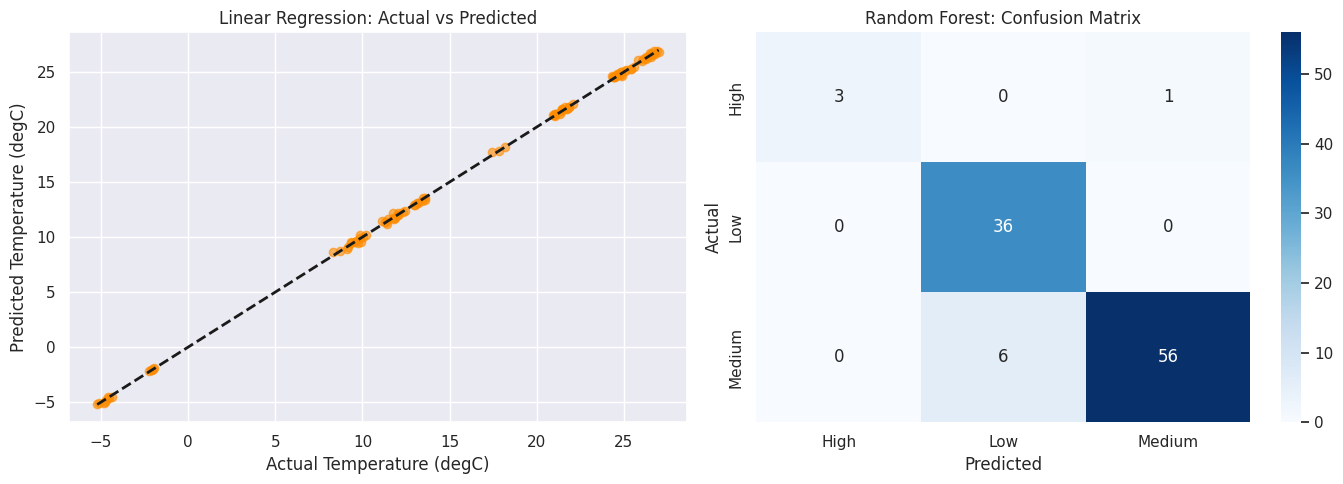

  Saved ML result plots to climate_project_files/ml_results.png

ANALYSIS COMPLETE -- see the 'climate_project_files' folder for
the CSV, JSON summary, SQLite DB, and dashboard images generated above.


In [ ]:
print("\n[SECTION R] Machine Learning")

# ---- Model 1: Linear Regression -> predict temperature ----
# One-hot encoding (not the LabelEncoder from Section L) is used for the
# "Country" feature here because linear models would otherwise treat the
# label-encoded integers as an ordinal scale, implying a false ranking
# between countries. One-hot columns act as per-country fixed effects.
country_dummies = pd.get_dummies(proc_df["Country"], prefix="is", drop_first=True)
X_reg = pd.concat([proc_df[["Year", "CO2_Emissions_MT",
                             "Renewable_Energy_Percent"]], country_dummies], axis=1)
y_reg = proc_df["Avg_Temperature_C"]

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_SEED)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lin_model = LinearRegression()
lin_model.fit(X_train_s, y_train)
y_pred = lin_model.predict(X_test_s)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("  Linear Regression (predict temperature):")
print(f"    R-squared = {r2:.4f}")
print(f"    RMSE      = {rmse:.3f} degC")
print("    (R-squared is very close to 1 here because the country dummy "
      "variables capture each country's baseline climate almost exactly -- "
      "this is a property of this simulated dataset, not something to "
      "expect with noisier real-world climate data. Be ready to explain "
      "this reasoning in your viva.)")

# ---- Model 2: Random Forest -> classify Risk_Level ----
X_clf = proc_df[["Avg_Temperature_C", "CO2_Emissions_MT",
                  "Extreme_Weather_Events", "Renewable_Energy_Percent"]]
y_clf = proc_df["Risk_Level"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_SEED, stratify=y_clf)

clf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED)
clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)

print("\n  Random Forest Classifier (predict Risk_Level):")
print(f"    Accuracy = {accuracy_score(yc_test, yc_pred):.3f}")
print(classification_report(yc_test, yc_pred))

importances = pd.Series(clf.feature_importances_, index=X_clf.columns) \
                .sort_values(ascending=False)
print("  Feature importances:")
print(importances)

# ---- ML result plots ----
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5))

axes2[0].scatter(y_test, y_pred, alpha=0.6, color="darkorange")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes2[0].plot(lims, lims, "k--", lw=2)
axes2[0].set_xlabel("Actual Temperature (degC)")
axes2[0].set_ylabel("Predicted Temperature (degC)")
axes2[0].set_title("Linear Regression: Actual vs Predicted")

cm = confusion_matrix(yc_test, yc_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=clf.classes_, yticklabels=clf.classes_, ax=axes2[1])
axes2[1].set_xlabel("Predicted")
axes2[1].set_ylabel("Actual")
axes2[1].set_title("Random Forest: Confusion Matrix")

plt.tight_layout()
ml_fig_path = os.path.join(DATA_DIR, "ml_results.png")
plt.savefig(ml_fig_path, dpi=150)
plt.show()
print(f"  Saved ML result plots to {ml_fig_path}")

print("\n" + "=" * 70)
print("ANALYSIS COMPLETE -- see the 'climate_project_files' folder for")
print("the CSV, JSON summary, SQLite DB, and dashboard images generated above.")
print("=" * 70)
